# 03 · Normalisation, feature selection and dimensionality reduction

**Why normalise?** UMI counts per cell vary ~10-fold because of capture and
sequencing efficiency, not biology. In addition, count variance grows with the
mean (Poisson / negative-binomial noise), so highly expressed genes would
dominate distances between cells.

* **Shifted logarithm** `log1p(counts / s · median)` (size-factor scaling then
  log) is simple and, in a systematic comparison of transformations,
  performed as well as more complex alternatives (Ahlmann-Eltze & Huber 2023,
  *Nat Methods*). It is used for visualisation, marker scoring and PCA.
* **Analytic Pearson residuals** (Lause *et al.* 2021, *Genome Biol*) are shown
  for comparison of variance stabilisation.
* Raw counts stay untouched in `layers["counts"]` for count-based models
  (scVI, pseudobulk edgeR/DESeq2).

**Feature selection.** Only genes with biological variability beyond the
technical expectation are informative for cell-type structure. We select 3,000
highly variable genes (HVGs) with the Seurat v3 variance-stabilising
transformation on raw counts, *per library* (`batch_key`), ranking genes that
are variable in many libraries first - this avoids picking batch-specific genes.
Only libraries with ≥500 cells vote, because the per-library loess fit is
numerically unstable for very small libraries (`ipfatlas.features.select_hvgs`).
Mitochondrial, ribosomal, haemoglobin and sex-chromosome genes are excluded
from the HVG set so that cells do not cluster by stress, donor sex or blood
contamination.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp

from ipfatlas import features
from ipfatlas.config import setup
from ipfatlas.plotting import (
    CONDITION_COLORS,
    SITE_COLORS,
    embedding_scatter,
    figsize,
    palette_for,
    panel_label,
    save_figure,
    set_style,
)
from ipfatlas.utils import write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "03_normalisation"
TAB = P.tables / "03_normalisation"
F = cfg["features"]

adata = sc.read_h5ad(P.interim / "discovery_qc.h5ad")
adata

AnnData object with n_obs × n_vars = 136437 × 24723
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier_counts', 'outlier_genes', 'outlier_top20', 'outlier_mito', 'outlier_hard', 'qc_fail', 'scDblFinder_score', 'scDblFinder_class', 'scDblFinder_doublet', 'scrublet_score', 'scrublet_doublet'
    var: 'gene_symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts'

## 1. Shifted-log normalisation

In [2]:
sc.pp.normalize_total(adata, target_sum=None)  # scale every cell to the median library size
sc.pp.log1p(adata)
adata.layers["log1p_norm"] = adata.X.copy()
print("median library size used as target:", np.median(adata.obs["total_counts"]))

median library size used as target: 4457.0


## 2. Mean-variance relationship: raw vs shifted log vs Pearson residuals
Computed on a random subsample of 20,000 cells for speed.

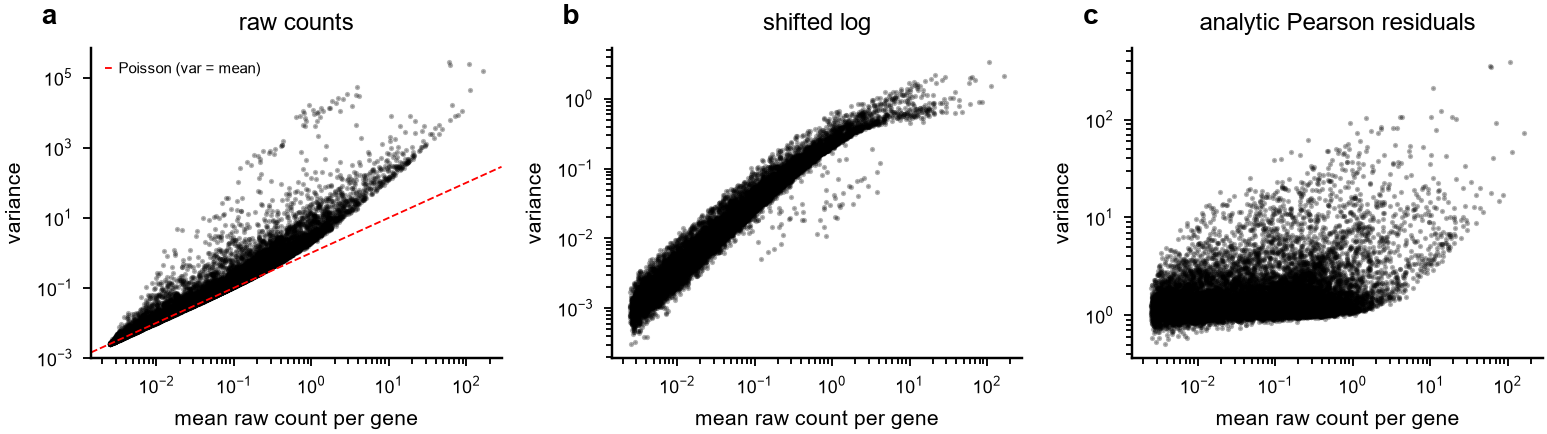

In [3]:
rng = np.random.default_rng(0)
sub = adata[np.sort(rng.choice(adata.n_obs, 20_000, replace=False))].copy()
sub = sub[:, np.asarray((sub.layers["counts"] > 0).sum(0)).ravel() >= 50].copy()


def mean_var(x):
    x = x.tocsc() if sp.issparse(x) else x
    m = np.asarray(x.mean(0)).ravel()
    m2 = np.asarray(x.multiply(x).mean(0)).ravel() if sp.issparse(x) else (x ** 2).mean(0)
    return m, m2 - m ** 2


m_raw, v_raw = mean_var(sub.layers["counts"])
m_log, v_log = mean_var(sub.layers["log1p_norm"])
pr = sc.experimental.pp.normalize_pearson_residuals(sub, layer="counts", inplace=False)["X"]
m_pr, v_pr = m_raw, pr.var(0)

fig, axes = plt.subplots(1, 3, figsize=figsize(183, 55))
for ax, (m, v, t) in zip(axes, [(m_raw, v_raw, "raw counts"), (m_raw, v_log, "shifted log"),
                                (m_pr, v_pr, "analytic Pearson residuals")]):
    ax.scatter(m, v, s=0.5, color="black", alpha=0.3, rasterized=True)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("mean raw count per gene")
    ax.set_ylabel("variance")
    ax.set_title(t)
axes[0].axline((1e-2, 1e-2), (1e1, 1e1), color="red", lw=0.6, ls="--", label="Poisson (var = mean)")
axes[0].legend(fontsize=5)
for a, l in zip(axes, "abc"):
    panel_label(a, l)
fig.tight_layout()
save_figure(fig, "S3_mean_variance_transformations", FIG)
plt.show()
del sub, pr

## 3. Cell-cycle scoring
S-phase and G2/M gene sets from Tirosh *et al.* 2016 (*Science*), as used in
Seurat. Proliferation is a biological signal here (e.g. proliferating
macrophages in IPF), so it is **scored, not regressed out**.

In [4]:
s_genes = ["MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6", "CDCA7", "DTL",
           "PRIM1", "UHRF1", "MLF1IP", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1", "GMNN", "WDR76", "SLBP",
           "CCNE2", "UBR7", "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2", "CDC45", "CDC6", "EXO1", "TIPIN",
           "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1", "CHAF1B", "BRIP1", "E2F8"]
g2m_genes = ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2", "CKS1B",
             "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A", "SMC4", "CCNB2", "CKAP2L", "CKAP2", "AURKB", "BUB1",
             "KIF11", "ANP32E", "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1", "CDC20", "TTK", "CDC25C",
             "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5", "CDCA2", "CDCA8", "ECT2", "KIF23", "HMMR", "AURKA", "PSRC1",
             "ANLN", "LBR", "CKAP5", "CENPE", "CTCF", "NEK2", "G2E3", "GAS2L3", "CBX5", "CENPA"]
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names], random_state=0)
adata.obs["phase"].value_counts(normalize=True).round(3)

phase
G1     0.619
S      0.337
G2M    0.044
Name: proportion, dtype: float64

## 4. Highly variable genes

In [5]:
hvg = features.select_hvgs(adata, F, batch_key="library_id")
print(f"{len(hvg)} HVGs; top-ranked: {', '.join(adata.var.loc[hvg].sort_values('highly_variable_rank').index[:25])}")
write_table(adata.var.loc[hvg, ["highly_variable_rank", "highly_variable_nbatches"]].sort_values(
    "highly_variable_rank"), TAB / "highly_variable_genes")

03:04:38 | INFO | HVG selection: 129 nuisance genes excluded; 42/43 batches with >= 500 cells vote


3000 HVGs; top-ranked: SFTPA2, SCGB3A2, SFTPA1, BPIFB1, SCGB1A1, SPP1, SCGB3A1, CCL2, FABP4, PTGDS, CCL18, ACKR1, CCL4L2, TPSAB1, C20orf85, MGP, SFTPC, CCL17, CCL4, DCN, SLPI, KRT17, GNLY, FCN3, NAPSA


WindowsPath('J:/Portfolio_projects/Projects/scRNA/results/tables/03_normalisation/highly_variable_genes.csv')

In [6]:
canonical = ["SFTPC", "AGER", "KRT5", "KRT17", "SCGB1A1", "FOXJ1", "COL1A1", "PECAM1", "PTPRC", "MARCO",
             "SPP1", "CD3E", "MS4A1", "CTHRC1", "MMP7", "ACTA2"]
pd.Series({g: bool(adata.var.loc[g, "highly_variable"]) for g in canonical if g in adata.var_names},
          name="selected as HVG")

SFTPC      True
AGER       True
KRT5       True
KRT17      True
SCGB1A1    True
FOXJ1      True
COL1A1     True
PECAM1     True
PTPRC      True
MARCO      True
SPP1       True
CD3E       True
MS4A1      True
CTHRC1     True
MMP7       True
ACTA2      True
Name: selected as HVG, dtype: bool

## 5. PCA (unintegrated)

J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


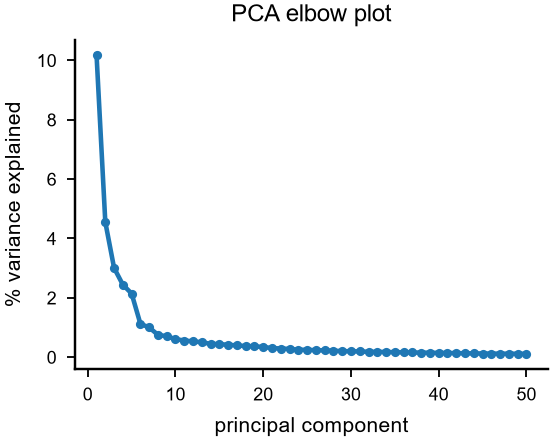

In [7]:
# genes are z-scored (clipped at 10 SD) on an HVG-only copy so .X stays sparse
hv = adata[:, hvg].copy()
sc.pp.scale(hv, max_value=10)
sc.pp.pca(hv, n_comps=F["n_pcs"], svd_solver="arpack", random_state=0)
adata.obsm["X_pca"] = hv.obsm["X_pca"]
adata.uns["pca"] = hv.uns["pca"]
del hv

fig, ax = plt.subplots(figsize=figsize(70, 50))
vr = adata.uns["pca"]["variance_ratio"]
ax.plot(np.arange(1, len(vr) + 1), vr * 100, "o-", ms=2)
ax.set_xlabel("principal component")
ax.set_ylabel("% variance explained")
ax.set_title("PCA elbow plot")
save_figure(fig, "S3_pca_elbow", FIG)
plt.show()

## 6. Unintegrated embedding — is there a batch effect?
Before correction, cells of the same type from different libraries/sites
separate. This visual check motivates integration (Notebook 04).

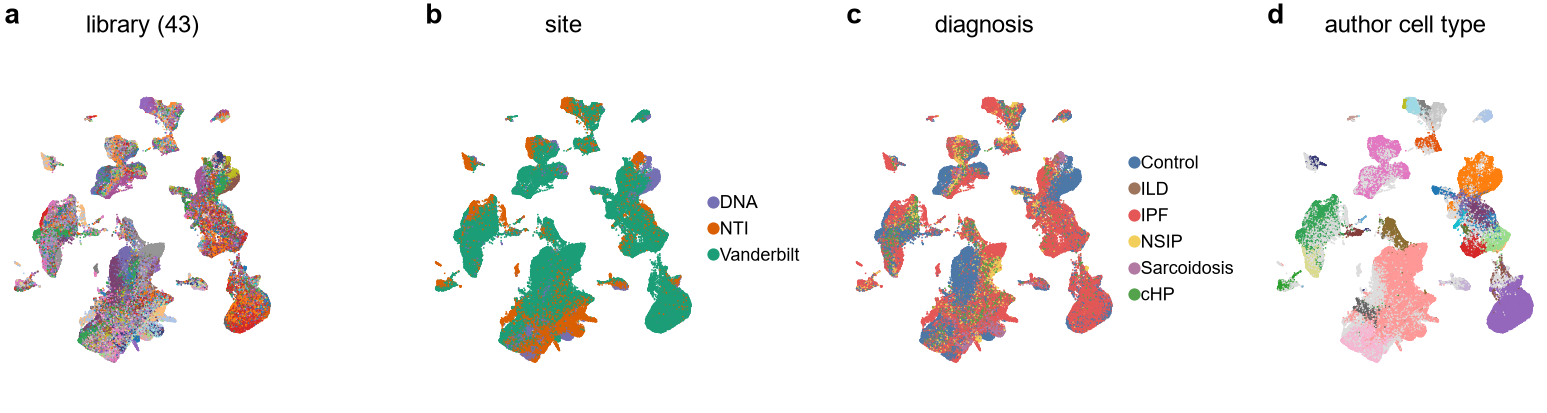

In [8]:
sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=15, random_state=0)
sc.tl.umap(adata, min_dist=0.3, random_state=0)
adata.obsm["X_umap_unintegrated"] = adata.obsm["X_umap"].copy()

fig, axes = plt.subplots(1, 4, figsize=figsize(183, 52))
xy = adata.obsm["X_umap_unintegrated"]
embedding_scatter(axes[0], xy, adata.obs["library_id"], s=0.3)
axes[0].set_title("library (43)")
embedding_scatter(axes[1], xy, adata.obs["site"], palette=SITE_COLORS, s=0.3, legend=True)
axes[1].set_title("site")
embedding_scatter(axes[2], xy, adata.obs["diagnosis"], palette=CONDITION_COLORS, s=0.3, legend=True)
axes[2].set_title("diagnosis")
ac = adata.obs["author_celltype"].cat.add_categories("not in author set").fillna("not in author set")
embedding_scatter(axes[3], xy, ac, palette=palette_for(ac.cat.categories, {"not in author set": "#DDDDDD"}), s=0.3)
axes[3].set_title("author cell type")
for a, l in zip(axes, "abcd"):
    panel_label(a, l, x=0.0)
fig.tight_layout()
save_figure(fig, "S3_umap_unintegrated", FIG)
plt.show()

In [9]:
adata.X = adata.layers["log1p_norm"]
adata.write_h5ad(P.interim / "discovery_norm.h5ad", compression="lzf")
adata

AnnData object with n_obs × n_vars = 136437 × 24723
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier_counts', 'outlier_genes', 'outlier_top20', 'outlier_mito', 'outlier_hard', 'qc_fail', 'scDblFinder_score', 'scDblFinder_class', 'scDblFinder_doublet', 'scrublet_score', 'scrublet_doublet', 'S_score', 'G2M_score', 'phase'
    var: 'gene_symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'log